# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

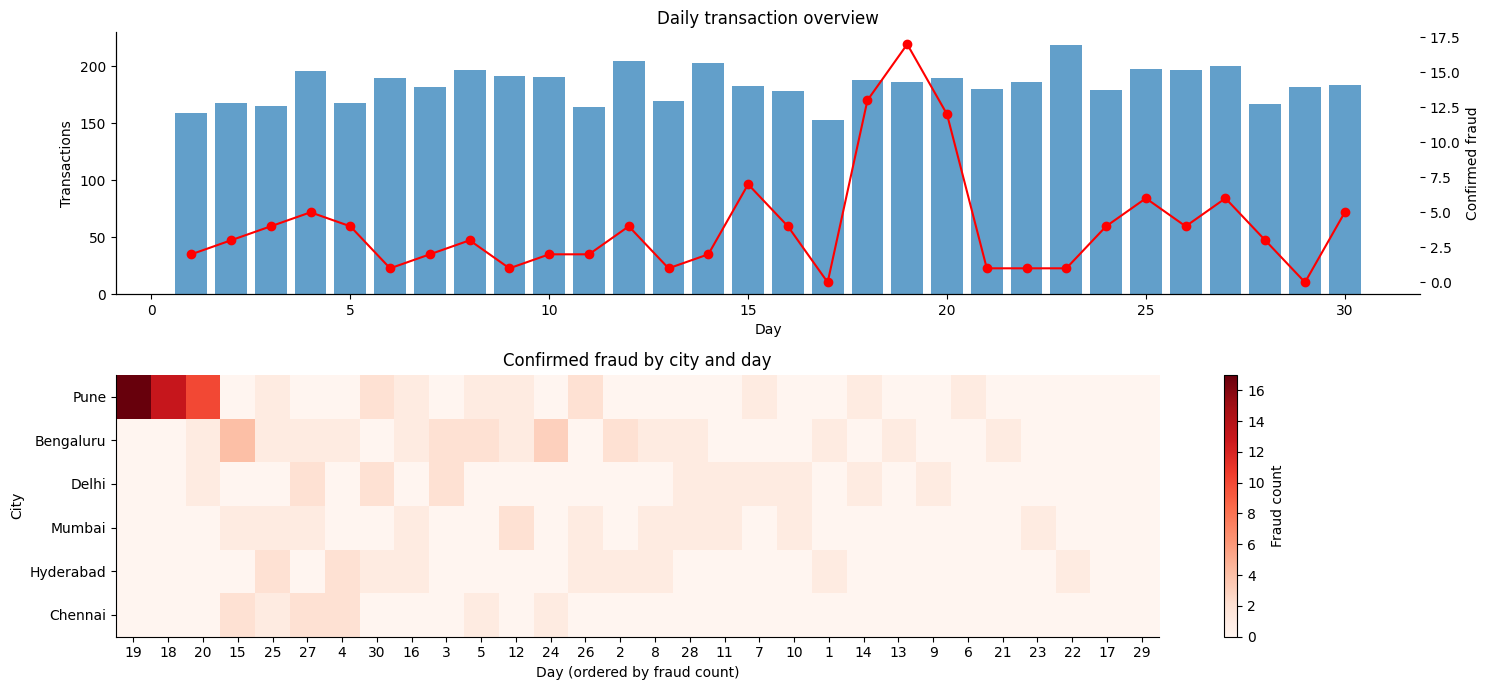

Top city-day cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
dtype: int64


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1: daily volume and confirmed fraud
daily = tx.groupby("day").agg(transactions=("txn_id", "count"), fraud=("is_fraud", "sum"))
axes[0].bar(daily.index, daily["transactions"], label="Transactions", alpha=0.7)
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily["fraud"], color="red", marker="o", label="Confirmed fraud")
axes[0].set(xlabel="Day", ylabel="Transactions", title="Daily transaction overview")
ax2.set_ylabel("Confirmed fraud")

# TODO 2: reorder city and day by fraud totals
heat = tx.pivot_table(index="city", columns="day", values="is_fraud", aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
heat = heat[heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_yticks(range(len(heat.index)), heat.index)
axes[1].set_xticks(range(len(heat.columns)), heat.columns)
axes[1].set(xlabel="Day (ordered by fraud count)", ylabel="City", title="Confirmed fraud by city and day")
fig.colorbar(im, ax=axes[1], label="Fraud count")
plt.tight_layout(); plt.show()

# TODO 3
print("Top city-day cells:")
print(tx[tx.is_fraud.eq(1)].groupby(["city", "day"]).size().sort_values(ascending=False).head(5))

**Your answer:** The overview shows when and where fraud clusters, which a score-sorted alert list hides. Reordering the matrix uses **pattern finding / reordered matrix** (Slide 39).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

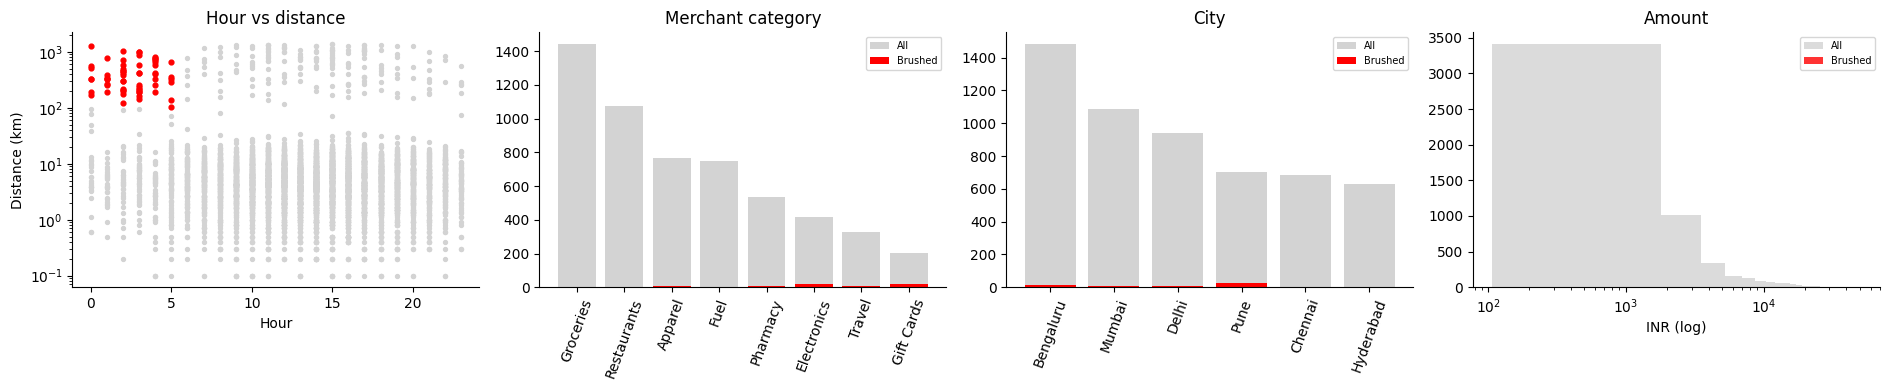

Brushed: 61; fraud rate inside: 86.9%; overall: 2.2%; share of all fraud captured: 44.2%


In [5]:
# TODO 1
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"].clip(lower=0.1), c="lightgrey", s=8)
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"].clip(lower=0.1), c="red", s=12)
axes[0].set(yscale="log", xlabel="Hour", ylabel="Distance (km)", title="Hour vs distance")
for col, ax, title in [("merchant_category", axes[1], "Merchant category"), ("city", axes[2], "City")]:
    counts = tx[col].value_counts().index
    all_counts = tx[col].value_counts().reindex(counts, fill_value=0)
    brush_counts = tx.loc[brush, col].value_counts().reindex(counts, fill_value=0)
    x = np.arange(len(counts)); ax.bar(x, all_counts, color="lightgrey", label="All")
    ax.bar(x, brush_counts, color="red", label="Brushed")
    ax.set_xticks(x, counts, rotation=70); ax.set_title(title); ax.legend(fontsize=7)
axes[3].hist(tx["amount_inr"].clip(lower=1), bins=30, color="lightgrey", alpha=.8, label="All")
axes[3].hist(tx.loc[brush, "amount_inr"].clip(lower=1), bins=30, color="red", alpha=.8, label="Brushed")
axes[3].set_xscale("log"); axes[3].set(title="Amount", xlabel="INR (log)"); axes[3].legend(fontsize=7)
plt.tight_layout(); plt.show()

# TODO 3
n_brush = int(brush.sum())
rate_brush = tx.loc[brush, "is_fraud"].mean() if n_brush else 0
rate_all = tx["is_fraud"].mean()
share_fraud = tx.loc[brush, "is_fraud"].sum() / max(tx["is_fraud"].sum(), 1)
print(f"Brushed: {n_brush}; fraud rate inside: {rate_brush:.1%}; overall: {rate_all:.1%}; share of all fraud captured: {share_fraud:.1%}")

**Your answer:** A high fraud rate can still capture only a small share of all fraud, so this rule should not be used alone. The merchant-category and city views help reveal fraud outside the brush.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [6]:
big = pd.concat([tx] * int(np.ceil(1_000_000 / len(tx))), ignore_index=True).iloc[:1_000_000]

# TODO 1
query = lambda df: (df["detector_score"] >= 0.6) & (df["amount_inr"] > 3000)
times = []
for _ in range(5):
    start = time.perf_counter(); query(big); times.append(time.perf_counter() - start)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6
max_rows = 0.1 / (best_s / len(big))

# TODO 3
t_50m = (best_s / len(big)) * 50_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100) if t_50m else 0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,000,000 rows in 2.3 ms -> 0.0023 us/row -> max 43,334,522 rows in 0.1 s
50M rows -> 0.12 s; must skip 13.3% of rows to stay under 0.1 s


**Your answer:** Use **sampling or pre-aggregation** to reduce work. It improves speed but may hide rare fraud cases or fine-grained transaction details.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

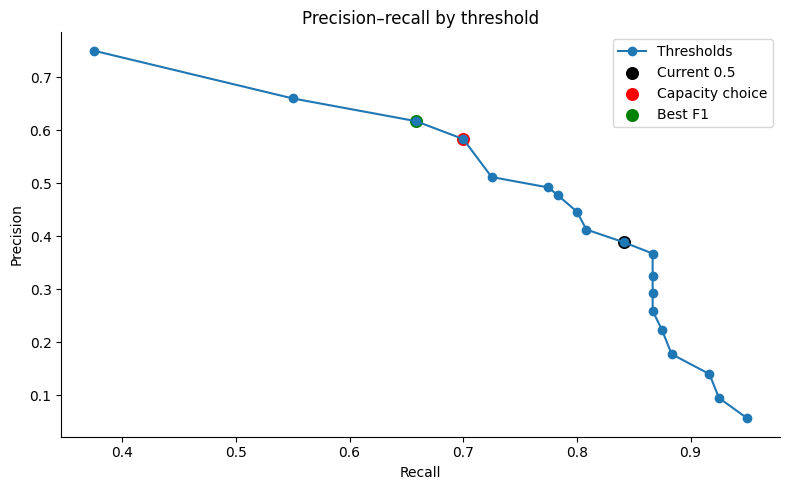

Recommend threshold 0.80: 144 alerts, precision 58.3%, recall 70.0%; Head of Fraud Ops should approve the trade-off.


In [7]:
rows = []
y = tx["is_fraud"].to_numpy()
for threshold in np.arange(0.05, 1.00, 0.05):
    pred = tx["detector_score"].to_numpy() >= threshold
    tp = int(((pred) & (y == 1)).sum()); fp = int(((pred) & (y == 0)).sum()); fn = int(((~pred) & (y == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
    rows.append({"threshold": round(float(threshold), 2), "alerts": int(pred.sum()), "TP": tp, "FP": fp, "FN": fn, "precision": precision, "recall": recall, "F1": f1})
pr = pd.DataFrame(rows)

# TODO 2
eligible = pr[pr.alerts <= 150]
capacity_choice = eligible.sort_values(["recall", "threshold"], ascending=[False, False]).iloc[0]
best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Thresholds")
for row, label, color in [(pr.iloc[(pr.threshold-0.5).abs().argmin()], "Current 0.5", "black"), (capacity_choice, "Capacity choice", "red"), (best_f1, "Best F1", "green")]:
    ax.scatter(row["recall"], row["precision"], label=label, color=color, s=70)
ax.set(xlabel="Recall", ylabel="Precision", title="Precision–recall by threshold"); ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommend threshold {capacity_choice.threshold:.2f}: {int(capacity_choice.alerts)} alerts, precision {capacity_choice.precision:.1%}, recall {capacity_choice.recall:.1%}; Head of Fraud Ops should approve the trade-off.")

**Your answer:** The Head of Fraud Ops should choose with the model’s metrics as evidence. Capacity, missed fraud, and investigation cost require human judgment; visual analytics supports, rather than replaces, that decision.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [8]:
# TODO 1
flagged = tx[tx["detector_score"] >= 0.3].copy()
fig = px.scatter(flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    title="Flagged transactions (score ≥ 0.3)")
fig.update_layout(dragmode="select")
fig.show()

# TODO 2
sun = tx.groupby(["city", "merchant_category"], as_index=False).agg(
    transactions=("txn_id", "count"), fraud_rate=("is_fraud", "mean"))
fig2 = px.sunburst(sun, path=["city", "merchant_category"], values="transactions", color="fraud_rate",
    color_continuous_scale="Reds", title="Drill down: city → merchant category (colour = fraud rate)")
fig2.show()

**Your answer:** Hovering over 400 cases one by one is slow and prevents pattern comparison. The overview heatmap and linked views show clusters across many cases at once.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Pune days 18–20: fraud rate 37.4%; outside 1.5%; chi-square p=1.06e-136


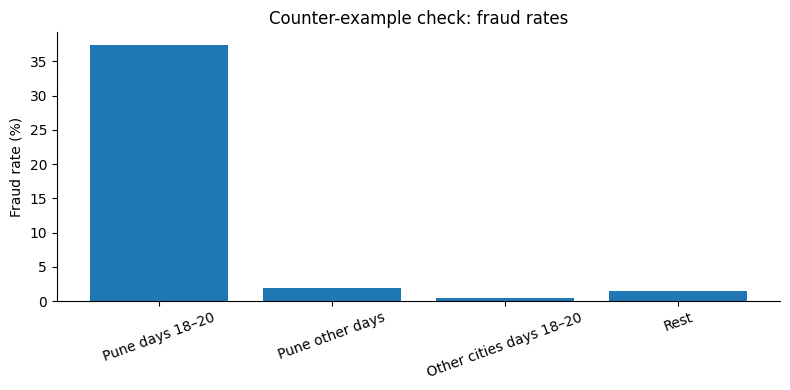

Verdict: cluster is statistically unusual; investigate, but do not assume a fraud ring.


In [9]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# Task 1's strongest cluster is Pune, days 18–20.
in_window = tx["city"].eq("Pune") & tx["day"].between(18, 20)

# TODO 2
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
tab = pd.crosstab(in_window, tx["is_fraud"])
chi2, p_value, _, _ = chi2_contingency(tab)
print(f"Pune days 18–20: fraud rate {rate_in:.1%}; outside {rate_out:.1%}; chi-square p={p_value:.3g}")

# TODO 3
same_city_other = tx[tx.city.eq("Pune") & ~tx.day.between(18, 20)]
other_cities_same = tx[~tx.city.eq("Pune") & tx.day.between(18, 20)]
rest = tx[~tx.city.eq("Pune") & ~tx.day.between(18, 20)]
groups = {
    "Pune days 18–20": tx.loc[in_window, "is_fraud"],
    "Pune other days": same_city_other["is_fraud"],
    "Other cities days 18–20": other_cities_same["is_fraud"],
    "Rest": rest["is_fraud"]
}

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
rates = {name: vals.mean() for name, vals in groups.items()}
ax.bar(list(rates.keys()), [v * 100 for v in rates.values()])
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Counter-example check: fraud rates")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict:", "cluster is statistically unusual; investigate, but do not assume a fraud ring." if p_value < 0.05 and rate_in > rate_out else "evidence is insufficient to support a fraud-ring hypothesis.")

**Your answer:** Either counter-example could weaken the hypothesis. If Pune has high fraud on other days, it may be a city-specific pattern; if other cities spike on days 18–20, a broader time-related cause is more likely.

**Your final note:** Last month, 120 of 5,520 transactions were confirmed fraud (2.2%), with a strong cluster in Pune on days 18–20. Choose the highest-recall threshold that stays within 150 alerts, then have the Head of Fraud Ops approve the precision–recall trade-off. Build the linked interactive scatter first for filtering and details-on-demand, supported by the overview heatmap. The 50-million-row filter needs indexing or pre-aggregation to meet the 0.1-second dynamic-query target. Add a feedback loop that feeds investigators’ confirmed outcomes back into detector retraining and threshold review.